# 01 · Single-Image Street-View Geolocalization Baselines (VS Code + Colab)
Keep notebooks, datasets, predictions, and metrics on local storage. Select a free Colab T4 runtime, upload the data ZIP via VS Code Explorer (**Upload to Colab**), and run the pilot dev split first.


## Data Filtering · Phase 0

**36 images form our custom cross-platform pilot.** OSV-5M is a global dataset whose official test CSV contains 210,122 rows. Filtering for France across three city bounding boxes yields 43 candidates around Paris, 23 around Lyon, and 29 around Toulouse. Below is the exact configuration and filter from [`scripts/prepare_pilot.py`](../scripts/prepare_pilot.py) (bounding box order: `west, south, east, north`).

```python
REGIONS = {
    "paris_area": (1.80, 48.30, 2.90, 49.40),
    "lyon_area": (4.28, 45.20, 5.38, 46.30),
    "toulouse_area": (0.89, 43.05, 1.99, 44.15),
}
DEV_PER_CITY = 3
HOLDOUT_PER_CITY = 3

def in_bbox(lat, lon, bbox):
    west, south, east, north = bbox
    return south <= lat <= north and west <= lon <= east

def osv_rows():
    with (ROOT / "data/raw/osv5m-test.csv").open(newline="", encoding="utf-8") as handle:
        for row in csv.DictReader(handle):
            if row["country"] != "FR":
                continue
            lat, lon = float(row["latitude"]), float(row["longitude"])
            for region, bbox in REGIONS.items():
                if in_bbox(lat, lon, bbox):
                    yield {
                        "id": row["id"], "latitude": lat, "longitude": lon, "region": region,
                        "sequence": row["sequence"], "license": "CC-BY-SA-4.0",
                        "attribution": row["creator_username"] or row["creator_id"],
                    }
```

`match_panorama_rows()` shuffles candidates with a fixed seed and pairs each eligible OSV sample with a geographically nearby Panoramax image, using each capture sequence at most once per source. The first 3 pairs per region go to `pilot_dev.jsonl` and the next 3 to `pilot_holdout.jsonl`, yielding **3 regions × 3 pairs × 2 images = 18 images** per split.


In [1]:
from pathlib import Path
import os
import subprocess
import sys
import torch

assert torch.cuda.is_available(), "Select Kernel → Colab → GPU → T4"
print("GPU:", torch.cuda.get_device_name(), "| PyTorch:", torch.__version__, flush=True)
RUNTIME = Path("/content/geoguessr-recognition")
RUNTIME.mkdir(parents=True, exist_ok=True)
os.environ["HF_HOME"] = str(RUNTIME / "hf-cache")
os.environ["HF_HUB_DISABLE_XET"] = "1"
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-cache-dir",
                "transformers==4.57.6", "accelerate==1.12.0", "bitsandbytes==0.48.2",
                "hydra-core==1.3.2", "peft==0.18.0"], check=True)

GPU: Tesla T4 | PyTorch: 2.14.1+cu130


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '--no-cache-dir', 'transformers==4.57.6', 'accelerate==1.12.0', 'bitsandbytes==0.48.2', 'hydra-core==1.3.2', 'peft==0.18.0'], returncode=0)

In [2]:
import json
import zipfile
from datetime import datetime, timezone

SPLIT = "pilot_dev"
LIMIT_PER_SOURCE = None  # Use e.g. 2 for a very short timed check.
archive_name = f"geoguessr-{SPLIT}.zip"
archives = sorted(Path("/content").rglob(archive_name))
if not archives:
    raise FileNotFoundError(f"Right-click {archive_name} in VS Code Explorer -> Upload to Colab")
project = RUNTIME / SPLIT
project.mkdir(exist_ok=True)
with zipfile.ZipFile(archives[0]) as archive:
    for item in archive.infolist():
        if not (project / item.filename).resolve().is_relative_to(project.resolve()):
            raise ValueError(f"Unsafe archive member: {item.filename}")
    archive.extractall(project)
sys.path.insert(0, str(project))
from phase1 import OSV_CODE, OSV_REV, PROMPT, QWEN, QWEN_REV, read_split, run_baseline, summarize

records = read_split(project / "data", SPLIT, LIMIT_PER_SOURCE)
run_dir = project / "results" / ("full" if LIMIT_PER_SOURCE is None else f"first-{LIMIT_PER_SOURCE}")
run_dir.mkdir(parents=True, exist_ok=True)
(run_dir / "run_config.json").write_text(json.dumps({
    "split": SPLIT, "limit_per_source": LIMIT_PER_SOURCE, "n": len(records), "prompt": PROMPT,
    "qwen_model": QWEN, "qwen_revision": QWEN_REV, "osv_revision": OSV_REV, "osv_code": OSV_CODE,
    "torch": torch.__version__, "gpu": torch.cuda.get_device_name(),
    "started_utc": datetime.now(timezone.utc).isoformat(),
}, indent=2))
print(f"Loaded {len(records)} checksum-verified images from {archive_name}")

Loaded 18 checksum-verified images from geoguessr-pilot_dev.zip


## VLM zero-shot · Qwen3‑VL‑2B 4-bit

In [3]:
run_baseline("qwen_zero_shot", records, run_dir, RUNTIME)
summarize(run_dir)

qwen_zero_shot: loading on Tesla T4


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (6 outputs left out)

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:464: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


qwen_zero_shot | osv5m | paris_area | 98.3 km
qwen_zero_shot | osv5m | paris_area | 206.6 km
qwen_zero_shot | osv5m | paris_area | 269.0 km
qwen_zero_shot | osv5m | lyon_area | 750.4 km
qwen_zero_shot | osv5m | lyon_area | 367.6 km
qwen_zero_shot | osv5m | lyon_area | 280.4 km
qwen_zero_shot | osv5m | toulouse_area | 462.3 km
qwen_zero_shot | osv5m | toulouse_area | 4870.6 km
qwen_zero_shot | osv5m | toulouse_area | 44.1 km
qwen_zero_shot | panoramax | paris_area | 539.9 km
qwen_zero_shot | panoramax | paris_area | 6652.7 km
qwen_zero_shot | panoramax | paris_area | 267.6 km
qwen_zero_shot | panoramax | lyon_area | 653.4 km
qwen_zero_shot | panoramax | lyon_area | 363.7 km
qwen_zero_shot | panoramax | lyon_area | 257.1 km
qwen_zero_shot | panoramax | toulouse_area | 230.2 km
qwen_zero_shot | panoramax | toulouse_area | 609.0 km
qwen_zero_shot | panoramax | toulouse_area | 464.5 km
method,source,n,n_valid,hit_25,hit_200,median_km_valid
qwen_zero_shot,osv5m,9,9,0.0,0.2222222222222222,280

{('qwen_zero_shot', 'osv5m'): {'method': 'qwen_zero_shot',
  'source': 'osv5m',
  'n': 9,
  'n_valid': 9,
  'hit_25': 0.0,
  'hit_200': 0.2222222222222222,
  'median_km_valid': 280.41406632963566},
 ('qwen_zero_shot', 'panoramax'): {'method': 'qwen_zero_shot',
  'source': 'panoramax',
  'n': 9,
  'n_valid': 9,
  'hit_25': 0.0,
  'hit_200': 0.0,
  'median_km_valid': 464.4827924564602}}

## Official OSV-5M Localization Baseline


In [4]:
run_baseline("osv5m_official", records, run_dir, RUNTIME)
summarize(run_dir)

osv5m_official: loading on Tesla T4


config.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.30G [00:00<?, ?B/s]

osv5m_official | osv5m | paris_area | 95.6 km
osv5m_official | osv5m | paris_area | 884.8 km
osv5m_official | osv5m | paris_area | 158.1 km
osv5m_official | osv5m | lyon_area | 1129.3 km
osv5m_official | osv5m | lyon_area | 328.6 km
osv5m_official | osv5m | lyon_area | 10.7 km
osv5m_official | osv5m | toulouse_area | 32.5 km
osv5m_official | osv5m | toulouse_area | 1680.6 km
osv5m_official | osv5m | toulouse_area | 3.8 km
osv5m_official | panoramax | paris_area | 670.1 km
osv5m_official | panoramax | paris_area | 962.2 km
osv5m_official | panoramax | paris_area | 1074.9 km
osv5m_official | panoramax | lyon_area | 548.3 km
osv5m_official | panoramax | lyon_area | 567.3 km
osv5m_official | panoramax | lyon_area | 481.8 km
osv5m_official | panoramax | toulouse_area | 224.4 km
osv5m_official | panoramax | toulouse_area | 10.7 km
osv5m_official | panoramax | toulouse_area | 206.7 km
method,source,n,n_valid,hit_25,hit_200,median_km_valid
osv5m_official,osv5m,9,9,0.2222222222222222,0.55555555

{('osv5m_official', 'osv5m'): {'method': 'osv5m_official',
  'source': 'osv5m',
  'n': 9,
  'n_valid': 9,
  'hit_25': 0.2222222222222222,
  'hit_200': 0.5555555555555556,
  'median_km_valid': 158.1070880316725},
 ('osv5m_official', 'panoramax'): {'method': 'osv5m_official',
  'source': 'panoramax',
  'n': 9,
  'n_valid': 9,
  'hit_25': 0.1111111111111111,
  'hit_200': 0.1111111111111111,
  'median_km_valid': 548.2597761813355},
 ('qwen_zero_shot', 'osv5m'): {'method': 'qwen_zero_shot',
  'source': 'osv5m',
  'n': 9,
  'n_valid': 9,
  'hit_25': 0.0,
  'hit_200': 0.2222222222222222,
  'median_km_valid': 280.41406632963566},
 ('qwen_zero_shot', 'panoramax'): {'method': 'qwen_zero_shot',
  'source': 'panoramax',
  'n': 9,
  'n_valid': 9,
  'hit_25': 0.0,
  'hit_200': 0.0,
  'median_km_valid': 464.4827924564602}}

## Export Results Locally
Locate the exported ZIP below in the Colab Explorer, download it, and save it into the project's `results/` folder.


In [5]:
import shutil

metrics = summarize(run_dir)
expected = {(m, s) for m in ("qwen_zero_shot", "osv5m_official") for s in ("osv5m", "panoramax")}
expected_count = {source: sum(r["source"] == source for r in records) for source in ("osv5m", "panoramax")}
complete = set(metrics) == expected and all(v["n"] == expected_count[v["source"]] for v in metrics.values())
suffix = "results" if complete else "partial-results"
print(shutil.make_archive(f"/content/phase1-{SPLIT}-{suffix}", "zip", root_dir=run_dir))

method,source,n,n_valid,hit_25,hit_200,median_km_valid
osv5m_official,osv5m,9,9,0.2222222222222222,0.5555555555555556,158.1070880316725
osv5m_official,panoramax,9,9,0.1111111111111111,0.1111111111111111,548.2597761813355
qwen_zero_shot,osv5m,9,9,0.0,0.2222222222222222,280.41406632963566
qwen_zero_shot,panoramax,9,9,0.0,0.0,464.4827924564602

/content/phase1-pilot_dev-results.zip


## Estimated GeoGuessr World Score · `pilot_dev`

Using the GeoGuessr World approximation from [PIGEON Supplement §H.2](https://openaccess.thecvf.com/content/CVPR2024/supplemental/Haas_PIGEON_Predicting_Image_CVPR_2024_supplemental.pdf), `score = 5000 * exp(-distance_km / 1492.7)`, averaged over 18 rounds and multiplied by 5:

| Method | Mean per Round | 5-Round Estimate |
|---|---:|---:|
| Qwen3-VL-2B zero-shot | 3,519 | 17,597 |
| Official OSV-5M baseline | 3,730 | 18,652 |
| Constant France centroid `(47.0, 2.5)` | 4,149 | 20,746 |

Guessing the center of France quantifies how geographic concentration inflates World scores even with `0/18` hits within 25 km. This table describes only the French pilot dev sample; global evaluation requires worldwide stratification.


## Qualitative Examples · Street-View Images & Predicted Coordinates

The plots below render saved `pilot_dev` predictions: the first two show geographically nearby Toulouse-area images from different platforms, and the third shows a cross-continental error near Paris. Each map displays ground truth alongside `Qwen3-VL-2B` zero-shot and official `osv5m/baseline` guesses, with dashed lines showing Haversine errors. Basemap: [Natural Earth](https://www.naturalearthdata.com/about/terms-of-use/).


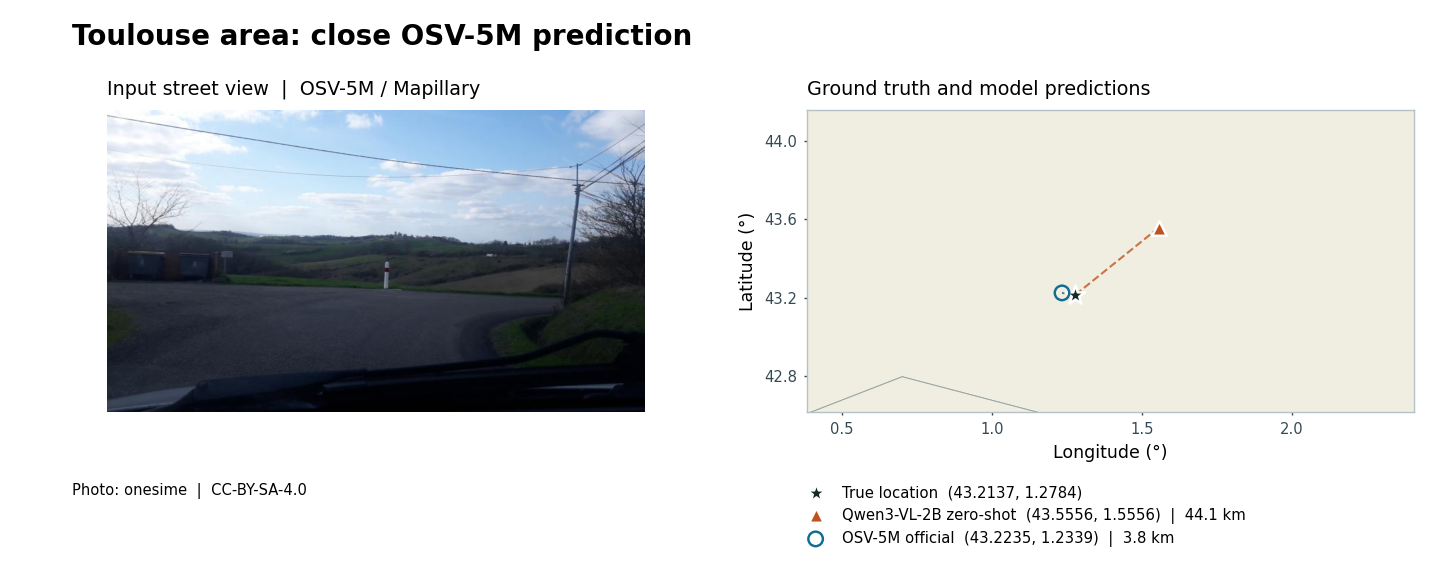

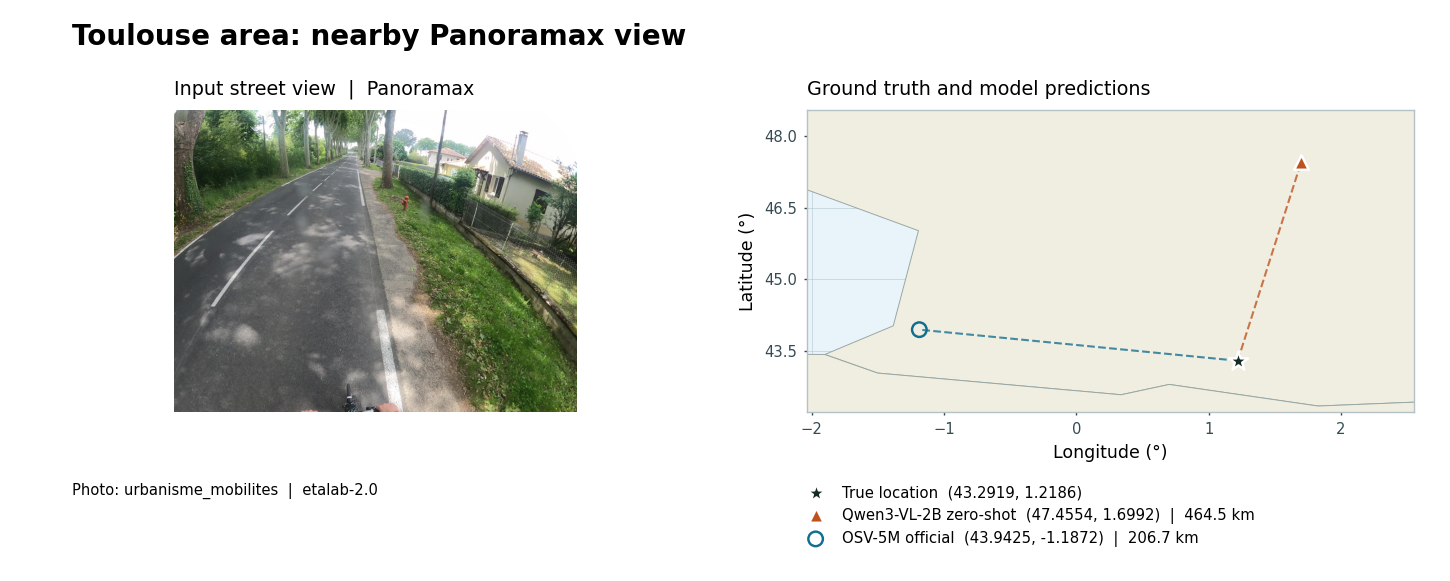

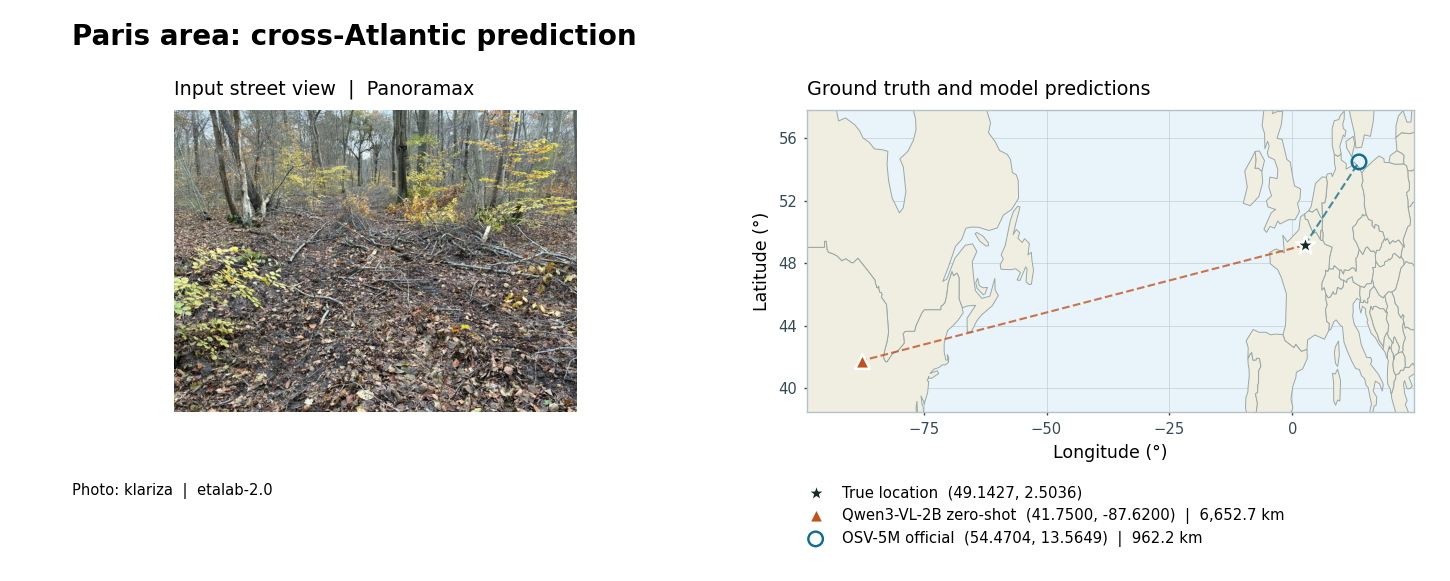

In [ ]:
from pathlib import Path
from urllib.request import urlopen
import json

import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.ticker import MaxNLocator
from PIL import Image, ImageOps

examples = [
    ("osv5m", "535650917847283", "Toulouse area: close OSV-5M prediction"),
    ("panoramax", "3d93e445-fa40-40cc-82a1-deda6a91b12d", "Toulouse area: nearby Panoramax view"),
    ("panoramax", "048cd542-2dea-47cf-b1ba-b6969f2652fb", "Paris area: cross-Atlantic prediction"),
]
models = {
    "qwen_zero_shot": ("Qwen3-VL-2B zero-shot", "#bf511d", "^"),
    "osv5m_official": ("OSV-5M official", "#106e91", "o"),
}
map_name = "ne_110m_admin_0_countries.geojson"
local_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/pilot/pilot_dev.jsonl").is_file()),
    None,
)
if local_root is not None:
    image_root = local_root / "data/pilot"
    result_root = local_root / "results/phase1-pilot_dev-results"
    basemap_path = local_root / "data/raw" / map_name
else:
    colab_project = Path("/content/geoguessr-recognition/pilot_dev")
    image_root = colab_project / "data"
    result_root = colab_project / "results/full"
    basemap_path = image_root / map_name

def load_rows(path):
    return {
        (row["source"], row["id"]): row
        for line in path.read_text(encoding="utf-8").splitlines()
        if line.strip()
        for row in [json.loads(line)]
    }

photos = load_rows(image_root / "pilot_dev.jsonl")
predictions = {method: load_rows(result_root / f"{method}.jsonl") for method in models}

if not basemap_path.is_file():
    map_url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/v5.1.2/geojson/" + map_name
    with urlopen(map_url, timeout=25) as response:
        basemap_path.write_bytes(response.read())

features = json.loads(basemap_path.read_text(encoding="utf-8"))["features"]
outlines = []
for feature in features:
    geometry = feature["geometry"]
    polygons = [geometry["coordinates"]] if geometry["type"] == "Polygon" else geometry["coordinates"]
    outlines.extend(polygon[0] for polygon in polygons)

for provider, identifier, title in examples:
    key = (provider, identifier)
    row = photos[key]
    actual = (row["longitude"], row["latitude"])
    label = "OSV-5M / Mapillary" if provider == "osv5m" else "Panoramax"
    points = [("True location", "#162a26", "*", actual, None)]
    for method, (model_label, color, marker) in models.items():
        guess = predictions[method][key]
        points.append((
            model_label, color, marker,
            (guess["guess_longitude"], guess["guess_latitude"]), guess["distance_km"],
        ))

    fig, (photo_ax, map_ax) = plt.subplots(1, 2, figsize=(11.6, 4.65))
    fig.subplots_adjust(left=0.05, right=0.975, top=0.81, bottom=0.29, wspace=0.21)
    fig.suptitle(title, x=0.05, y=0.96, ha="left", fontsize=16, fontweight="bold")
    with Image.open(image_root / row["image"]) as image:
        photo_ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))
    photo_ax.set_title(f"Input street view  |  {label}", loc="left", fontsize=11, pad=9)
    photo_ax.set_axis_off()
    credit_ax = fig.add_axes([0.05, 0.105, 0.40, 0.075], frameon=False)
    credit_ax.set_axis_off()
    credit_ax.text(0, 0.85, f"Photo: {row['attribution'].strip()}  |  {row['license']}", va="top", fontsize=8.5, wrap=True)

    map_ax.set_title("Ground truth and model predictions", loc="left", fontsize=11, pad=9)
    map_ax.set_facecolor("#e9f4fa")
    map_ax.add_collection(PolyCollection(
        outlines, facecolor="#f0eee1", edgecolor="#97a6a4", linewidth=0.55, zorder=1,
    ))
    for _, color, _, point, _ in points[1:]:
        map_ax.plot([actual[0], point[0]], [actual[1], point[1]], "--", color=color, alpha=0.78, linewidth=1.2, zorder=3)
    for text, color, marker, (lon, lat), distance in points:
        error = "" if distance is None else f"  |  {distance:,.1f} km"
        map_ax.scatter(lon, lat, s=135 if marker == "*" else 70, marker=marker,
                       facecolors="none" if marker == "o" else color,
                       edgecolors=color if marker == "o" else "white", linewidths=1.4,
                       zorder=5 if marker == "o" else 4,
                       label=f"{text}  ({lat:.4f}, {lon:.4f}){error}")

    xs, ys = zip(*(point for _, _, _, point, _ in points))
    x_pad = max(0.85, (max(xs) - min(xs)) * 0.11)
    y_pad = max(0.60, (max(ys) - min(ys)) * 0.26)
    map_ax.set(xlim=(max(-180, min(xs) - x_pad), min(180, max(xs) + x_pad)),
               ylim=(max(-90, min(ys) - y_pad), min(90, max(ys) + y_pad)))
    map_ax.xaxis.set_major_locator(MaxNLocator(5))
    map_ax.yaxis.set_major_locator(MaxNLocator(5))
    map_ax.set_axisbelow(True)
    map_ax.grid(color="#b0c1c9", linewidth=0.55, alpha=0.55)
    for spine in map_ax.spines.values():
        spine.set_color("#b4c1c6")
    map_ax.tick_params(labelsize=8.5, colors="#344a54", length=2)
    map_ax.set(xlabel="Longitude (°)", ylabel="Latitude (°)")
    map_ax.legend(loc="upper left", bbox_to_anchor=(-0.02, -0.22), frameon=False,
                  borderaxespad=0.0, labelspacing=0.5, fontsize=8.6, scatterpoints=1)
    plt.show()
    plt.close(fig)